# NFL Narrative Analysis

In [41]:
import polars as pl
import nflreadpy as nfl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr

## Q1: Rushing and Passing Success Rates vs. Winning Percentage

### Data Preparation and Validation

In [42]:
# Load the 2025 NFL play-by-play dataset
playbyplay = nfl.load_pbp(2025)

# Restrict analysis to the 2025 regular season
pbp = playbyplay.filter(
    pl.col("season_type") == "REG"
)

print("Regular season plays:", pbp.height)
print("Regular season games:", pbp["game_id"].n_unique())

Regular season plays: 46452
Regular season games: 272


In [43]:
# Check whether play IDs are ordered within each game
ordering_check = (
    pbp.with_row_index("row_number")
    .group_by("game_id")
    .agg(
        pl.col("play_id").is_sorted().alias("plays_sorted")
    )
)

print("Total games:", ordering_check.height)
print(
    "Games with unsorted play IDs:",
    ordering_check.filter(~pl.col("plays_sorted")).height
)

Total games: 272
Games with unsorted play IDs: 272


In [44]:
# Scores from the original row ordering
original_scores = (
    pbp.group_by("game_id")
    .agg(
        pl.col("home_score").last().alias("original_home"),
        pl.col("away_score").last().alias("original_away")
    )
)

# Scores after sorting each game's plays by play_id
ordered_scores = (
    pbp.sort(["game_id", "play_id"])
    .group_by("game_id")
    .agg(
        pl.col("home_score").last().alias("ordered_home"),
        pl.col("away_score").last().alias("ordered_away")
    )
)

# Compare both approaches
score_comparison = original_scores.join(
    ordered_scores,
    on="game_id"
)

mismatches = score_comparison.filter(
    (pl.col("original_home") != pl.col("ordered_home")) |
    (pl.col("original_away") != pl.col("ordered_away"))
)

print("Total games compared:", score_comparison.height)
print("Games with different scores:", mismatches.height)

print(mismatches.head(10))

Total games compared: 272
Games with different scores: 0
shape: (0, 5)
┌─────────┬───────────────┬───────────────┬──────────────┬──────────────┐
│ game_id ┆ original_home ┆ original_away ┆ ordered_home ┆ ordered_away │
│ ---     ┆ ---           ┆ ---           ┆ ---          ┆ ---          │
│ str     ┆ i32           ┆ i32           ┆ i32          ┆ i32          │
╞═════════╪═══════════════╪═══════════════╪══════════════╪══════════════╡
└─────────┴───────────────┴───────────────┴──────────────┴──────────────┘


In [45]:
# Load official game-level results
schedules = nfl.load_schedules(2025).filter(
    pl.col("game_type") == "REG"
)

# Select final scores
official_scores = schedules.select(
    "game_id",
    pl.col("home_score").alias("official_home"),
    pl.col("away_score").alias("official_away")
)

# Compare play-by-play scores to schedule scores
verification = ordered_scores.join(
    official_scores,
    on="game_id",
    how="left"
)

# Check for unmatched games or score differences
problems = verification.filter(
    pl.col("official_home").is_null()
    | pl.col("official_away").is_null()
    | (pl.col("ordered_home") != pl.col("official_home"))
    | (pl.col("ordered_away") != pl.col("official_away"))
)

print("Games checked:", verification.height)
print("Games with missing or mismatched final scores:", problems.height)

print(problems.head(10))

Games checked: 272
Games with missing or mismatched final scores: 0
shape: (0, 5)
┌─────────┬──────────────┬──────────────┬───────────────┬───────────────┐
│ game_id ┆ ordered_home ┆ ordered_away ┆ official_home ┆ official_away │
│ ---     ┆ ---          ┆ ---          ┆ ---           ┆ ---           │
│ str     ┆ i32          ┆ i32          ┆ i32           ┆ i32           │
╞═════════╪══════════════╪══════════════╪═══════════════╪═══════════════╡
└─────────┴──────────────┴──────────────┴───────────────┴───────────────┘


In [46]:
# Calculate each team's win percentage
games = (
    pbp.group_by("game_id")
    .agg(
        pl.col("home_team").first(),
        pl.col("away_team").first(),
        pl.col("home_score").last(),
        pl.col("away_score").last()
    )
    .drop_nulls()
)

home = games.select(
    pl.col("home_team").alias("team"),
    (pl.col("home_score") > pl.col("away_score"))
        .cast(pl.Int64).alias("win")
)

away = games.select(
    pl.col("away_team").alias("team"),
    (pl.col("away_score") > pl.col("home_score"))
        .cast(pl.Int64).alias("win")
)

win_pct = (
    pl.concat([home, away])
    .group_by("team")
    .agg(pl.col("win").mean().alias("win_pct"))
)

# Calculate rushing and passing success rates
success_rates = (
    pbp.filter(
        pl.col("play_type").is_in(["run", "pass"])
        & pl.col("posteam").is_not_null()
        & pl.col("success").is_not_null()
    )
    .group_by(["posteam", "play_type"])
    .agg(
        pl.col("success").mean().alias("success_rate")
    )
    .join(
        win_pct,
        left_on="posteam",
        right_on="team"
    )
)

print("Number of teams:", success_rates["posteam"].n_unique())

success_rates.head()

Number of teams: 32


posteam,play_type,success_rate,win_pct
str,str,f64,f64
"""ARI""","""run""",0.403846,0.176471
"""ARI""","""pass""",0.443662,0.176471
"""NO""","""run""",0.393939,0.352941
"""NO""","""pass""",0.437795,0.352941
"""BUF""","""pass""",0.47698,0.705882


All game scores used to calculate team winning percentages were verified by comparing the play-by-play results with the nflverse schedules dataset. All 272 regular season games had matching final scores, with no missing or mismatched values. 

### Correlation Analysis

In [47]:
# Separate passing and rushing observations
pass_data = success_rates.filter(
    pl.col("play_type") == "pass"
)

rush_data = success_rates.filter(
    pl.col("play_type") == "run"
)

# Calculate Pearson correlations
pass_result = pearsonr(
    pass_data["success_rate"].to_numpy(),
    pass_data["win_pct"].to_numpy()
)

rush_result = pearsonr(
    rush_data["success_rate"].to_numpy(),
    rush_data["win_pct"].to_numpy()
)

print("Passing success vs. win percentage")
print(f"Pearson r: {pass_result.statistic:.4f}")
print(f"p-value: {pass_result.pvalue:.4f}")

print("\nRushing success vs. win percentage")
print(f"Pearson r: {rush_result.statistic:.4f}")
print(f"p-value: {rush_result.pvalue:.4f}")

Passing success vs. win percentage
Pearson r: 0.6296
p-value: 0.0001

Rushing success vs. win percentage
Pearson r: 0.3292
p-value: 0.0658


### Confidence Intervals

In [48]:
# Calculate 95% confidence intervals for Pearson correlations
pass_ci = pass_result.confidence_interval(confidence_level=0.95)
rush_ci = rush_result.confidence_interval(confidence_level=0.95)

print("Passing success vs. win percentage")
print(f"Pearson r: {pass_result.statistic:.4f}")
print(f"95% CI: [{pass_ci.low:.4f}, {pass_ci.high:.4f}]")

print("\nRushing success vs. win percentage")
print(f"Pearson r: {rush_result.statistic:.4f}")
print(f"95% CI: [{rush_ci.low:.4f}, {rush_ci.high:.4f}]")

Passing success vs. win percentage
Pearson r: 0.6296
95% CI: [0.3599, 0.8022]

Rushing success vs. win percentage
Pearson r: 0.3292
95% CI: [-0.0220, 0.6081]


### Alternative Explanations and Robustness Checks

In [49]:
# Create one row per team, with separate rushing and passing success rates
team_success = (
    success_rates
    .pivot(
        on="play_type",
        index="posteam",
        values="success_rate"
    )
    .rename({
        "pass": "pass_success_rate",
        "run": "rush_success_rate"
    })
    .drop_nulls()
)

# Calculate correlation between passing and rushing success
pass_rush_result = pearsonr(
    team_success["pass_success_rate"].to_numpy(),
    team_success["rush_success_rate"].to_numpy()
)

pass_rush_ci = pass_rush_result.confidence_interval(
    confidence_level=0.95
)

print("Passing success vs. rushing success")
print(f"Pearson r: {pass_rush_result.statistic:.4f}")
print(f"p-value: {pass_rush_result.pvalue:.4f}")
print(
    f"95% CI: [{pass_rush_ci.low:.4f}, "
    f"{pass_rush_ci.high:.4f}]"
)

Passing success vs. rushing success
Pearson r: 0.4142
p-value: 0.0184
95% CI: [0.0766, 0.6666]


In [50]:
import statsmodels.api as sm

# Combine team success rates with winning percentages
regression_data = team_success.join(
    win_pct,
    left_on="posteam",
    right_on="team"
)

# Independent variables
X = regression_data.select([
    "pass_success_rate",
    "rush_success_rate"
]).to_numpy()

# Dependent variable
y = regression_data["win_pct"].to_numpy()

# Add intercept
X = sm.add_constant(X)

# Fit multiple linear regression
model = sm.OLS(y, X).fit()

# Display regression results
print(model.summary(
    xname=["const", "pass_success_rate", "rush_success_rate"]
))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.402
Model:                            OLS   Adj. R-squared:                  0.361
Method:                 Least Squares   F-statistic:                     9.748
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           0.000578
Time:                        19:05:04   Log-Likelihood:                 14.234
No. Observations:                  32   AIC:                            -22.47
Df Residuals:                      29   BIC:                            -18.07
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.8943      0.39

The regression above supports the idea that passing success rate is significantly associated with NFL team win % in the 2025 regular season, even after accounting for rushing success. The coefficient of 2.65 shows a strong positive relation with a small p-value of 0.001. Rushing  did not show a statistically significant independent association with a coefficient of 0.482 and large p-value of 0.605. The model shows that 40.2% of the variation in team win % was due to the passing and rushing success rates.

#### First-Half-Only Analysis

In [51]:
# Filter to first-half rushing and passing plays
first_half = pbp.filter(
    (pl.col("qtr") <= 2)
    & pl.col("play_type").is_in(["run", "pass"])
    & pl.col("posteam").is_not_null()
    & pl.col("success").is_not_null()
)

# Calculate first-half success rates for each team
first_half_success = (
    first_half
    .group_by(["posteam", "play_type"])
    .agg(
        pl.col("success").mean().alias("success_rate")
    )
)

# Separate passing and rushing success rates
first_half_success = (
    first_half_success
    .pivot(
        on="play_type",
        index="posteam",
        values="success_rate"
    )
    .rename({
        "pass": "pass_success_rate",
        "run": "rush_success_rate"
    })
    .drop_nulls()
)

# Combine with team winning percentages
first_half_data = first_half_success.join(
    win_pct,
    left_on="posteam",
    right_on="team"
)

# Prepare regression variables
X_first = first_half_data.select([
    "pass_success_rate",
    "rush_success_rate"
]).to_numpy()

y_first = first_half_data["win_pct"].to_numpy()

X_first = sm.add_constant(X_first)

# Fit regression model
first_half_model = sm.OLS(y_first, X_first).fit()

print(first_half_model.summary(
    xname=["const", "pass_success_rate", "rush_success_rate"]
))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.360
Model:                            OLS   Adj. R-squared:                  0.316
Method:                 Least Squares   F-statistic:                     8.163
Date:                Mon, 16 Nov 2026   Prob (F-statistic):            0.00154
Time:                        19:05:04   Log-Likelihood:                 13.153
No. Observations:                  32   AIC:                            -20.31
Df Residuals:                      29   BIC:                            -15.91
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.6297      0.32

#### Take-away

During the 2025 NFL regular season, passing success rate demonstrated a stronger relationship with team win % than rushing success rate even after controlling for rushing success and considering first-half plays only. Rushing success did not demonstrate a statistically significant independent relationship with win % in either model.

### Final Figure

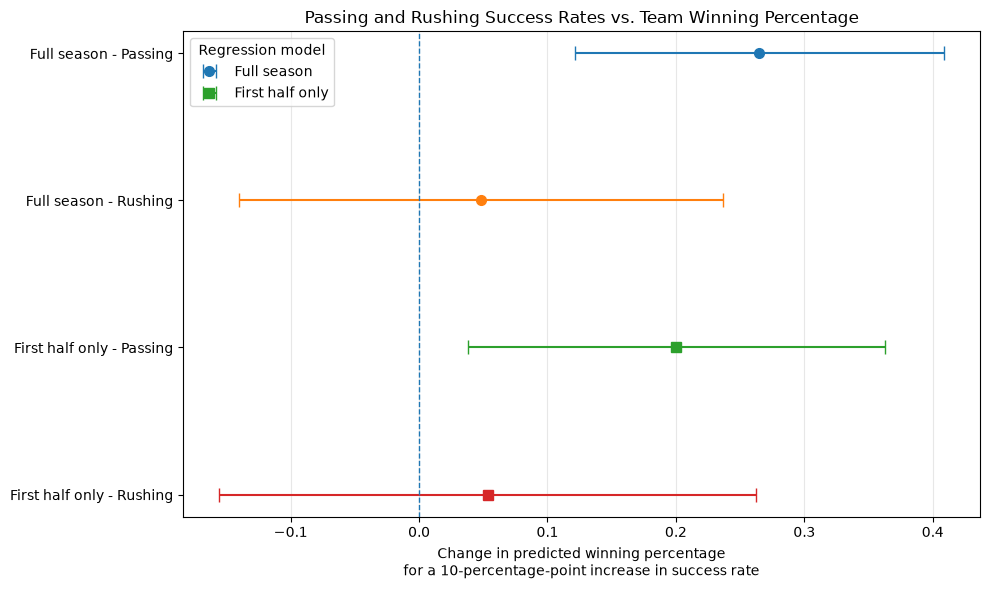

In [52]:

import numpy as np
import matplotlib.pyplot as plt
import os

# Store the coefficients and confidence intervals from both models.
# We multiply by 0.1 to represent a 10-percentage-point increase
# in the success rate rather than a full 1.0 (100 percentage points).

results = []

for model_name, fitted_model in [
    ("Full season", model),
    ("First half only", first_half_model)
]:
    coefficients = fitted_model.params
    confidence_intervals = fitted_model.conf_int()

    for index, predictor in [(1, "Passing"), (2, "Rushing")]:
        estimate = coefficients[index] * 0.1
        lower = confidence_intervals[index][0] * 0.1
        upper = confidence_intervals[index][1] * 0.1

        results.append({
            "model": model_name,
            "predictor": predictor,
            "estimate": estimate,
            "lower": lower,
            "upper": upper
        })

# Create the figure.
fig, ax = plt.subplots(figsize=(10, 6))

# Assign a separate vertical position to each result.
positions = [3, 2, 1, 0]

for i, result in enumerate(results):
    estimate = result["estimate"]

    # Calculate the distance from the estimate to each CI boundary.
    lower_error = estimate - result["lower"]
    upper_error = result["upper"] - estimate

    marker = "o" if result["model"] == "Full season" else "s"

    ax.errorbar(
        estimate,
        positions[i],
        xerr=[[lower_error], [upper_error]],
        fmt=marker,
        capsize=5,
        markersize=7,
        label=result["model"] if result["predictor"] == "Passing" else None
    )

# Add labels and formatting.
ax.set_yticks(positions)
ax.set_yticklabels([
    f'{r["model"]} - {r["predictor"]}'
    for r in results
])

ax.axvline(0, linestyle="--", linewidth=1)
ax.set_xlabel(
    "Change in predicted winning percentage\n"
    "for a 10-percentage-point increase in success rate"
)
ax.set_title(
    "Passing and Rushing Success Rates vs. Team Winning Percentage"
)
ax.legend(title="Regression model")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save the figure.
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/finding-one.png", dpi=300, bbox_inches="tight")

plt.show()


The figure shows that passing success rates have a positive and statistically significant association with team win %. Not only is there a positive relationship among all regular season games, but this still holds when using only first-half plays from those games, which means that the bias of late-game decisions is not the sole reason. On the other hand, rushing success rate is not statistically significant in either model, as shown by both confidence intervals including zero. Overall, the results suggest that passing success rate has a stronger association with team win % than rushing success rate in our analysis. 

# Q2: 4th Down Efficiency Going vs Punting

regression model for epa by 4th downs could be helpful:
epa ~ decision * (yards to go + yardline_100) 

additional questions to consider: time in the game definitely matters but not sure how much, as well as score deficit

In [53]:
# load 4th down data as done in other checkpoints
pbp5Years = nfl.load_pbp([2021, 2022, 2023, 2024, 2025])
pbp5Years = pbp5Years.filter(pl.col("week") <= 17)
pbp5Years = pbp5Years.select([
    "play_type", "yards_gained", "epa", "success", "down", "ydstogo",
    "yardline_100", "qtr", "posteam", "defteam", "game_id", "week"
])

fourthDowns = pbp5Years.filter(
    (pl.col("down") == 4)
    & (pl.col("play_type").is_in(["punt", "run", "pass"]))
)
fourthDowns = fourthDowns.with_columns(
    pl.when(pl.col("play_type") == "punt")
    .then(pl.lit("Punt"))
    .otherwise(pl.lit("Go for it"))
    .alias("decision")
)
fourthDowns

play_type,yards_gained,epa,success,down,ydstogo,yardline_100,qtr,posteam,defteam,game_id,week,decision
str,f64,f64,f64,f64,f64,f64,f64,str,str,str,i32,str
"""punt""",0.0,-0.345293,0.0,4.0,10.0,75.0,1.0,"""TEN""","""ARI""","""2021_01_ARI_TEN""",1,"""Punt"""
"""punt""",0.0,0.449995,1.0,4.0,16.0,81.0,1.0,"""TEN""","""ARI""","""2021_01_ARI_TEN""",1,"""Punt"""
"""punt""",0.0,-0.576709,0.0,4.0,3.0,58.0,1.0,"""ARI""","""TEN""","""2021_01_ARI_TEN""",1,"""Punt"""
"""pass""",6.0,3.062272,1.0,4.0,4.0,74.0,1.0,"""TEN""","""ARI""","""2021_01_ARI_TEN""",1,"""Go for it"""
"""punt""",0.0,0.006464,1.0,4.0,17.0,75.0,1.0,"""TEN""","""ARI""","""2021_01_ARI_TEN""",1,"""Punt"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""punt""",0.0,0.800151,1.0,4.0,7.0,62.0,4.0,"""TB""","""MIA""","""2025_17_TB_MIA""",17,"""Punt"""
"""punt""",0.0,-0.139205,0.0,4.0,1.0,73.0,4.0,"""MIA""","""TB""","""2025_17_TB_MIA""",17,"""Punt"""
"""punt""",0.0,-0.035621,0.0,4.0,11.0,75.0,4.0,"""MIA""","""TB""","""2025_17_TB_MIA""",17,"""Punt"""


In [54]:
# consider columns relevant for this model: epa, ydstogo, yardline_100, decision
fourthDowns = fourthDowns.select([
    "epa", "ydstogo", "yardline_100", "decision"
])
# dummy variable for fourth downs: punt = 0, go = 1
fourthDowns = fourthDowns.with_columns(
    pl.when(pl.col("decision") == "Punt")
    .then(pl.lit(0))
    .otherwise(pl.lit(1))
    .alias("decision_dummy")
)
fourthDowns.describe()

statistic,epa,ydstogo,yardline_100,decision,decision_dummy
str,f64,f64,f64,str,f64
"""count""",13598.0,13598.0,13598.0,"""13598""",13598.0
"""null_count""",0.0,0.0,0.0,"""0""",0.0
"""mean""",-0.059972,7.751287,58.079056,null,0.272467
"""std""",1.764714,6.074498,20.712363,null,0.445245
"""min""",-11.448006,1.0,1.0,"""Go for it""",0.0
"""25%""",-0.658847,3.0,47.0,null,0.0
"""50%""",-0.10095,6.0,61.0,null,0.0
"""75%""",0.526484,11.0,72.0,null,1.0
"""max""",8.22722,40.0,99.0,"""Punt""",1.0


In [55]:
# create a regression model for epas on 4th down decisions, controlling for yards to go and field position
fourthPredictors = fourthDowns.select([
    "decision_dummy",
    "ydstogo",
    "yardline_100"
]).to_numpy()
fourthPredictors = sm.add_constant(fourthPredictors)

fourthResponse = fourthDowns["epa"].to_numpy()

fourthModel = sm.OLS(fourthResponse, fourthPredictors).fit()
print(fourthModel.summary(
    xname=["intercept", "decision_dummy", "ydstogo", "yardline_100"]
))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     13.35
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.07e-08
Time:                        19:05:07   Log-Likelihood:                -26998.
No. Observations:               13598   AIC:                         5.400e+04
Df Residuals:                   13594   BIC:                         5.403e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
intercept         -0.2725      0.066     -4.

decision on its own accounts for a 0.244 increase in EPA: going for it on average results in a play 0.244 EPA higher than punting when all other factors are constant. Generally more EPA when there's less yards to go as well, which makes sense (negative coefficient for this means that the more yards from a first down, the less EPA on average a play produces), as well as higher on average when closer to the endzone. however, yards to go is not a very significant predictor at a significance level of 0.05

inspired from a jon bois video i watched, the regions around the 45-35 yard line of the opponent are usually fairly even in terms of go or punt decisions, so i want to control for that

### Controlling for plays from middle yard line decisions

In [56]:
# filter to plays from around 45-35 yardline_100, as these usually produce the most equal number of punts and go-for-its
fourthDownsMiddle = fourthDowns.filter(
    (pl.col("yardline_100") >= 35) & (pl.col("yardline_100") <= 45)
)
fourthDownsMiddle.describe()

statistic,epa,ydstogo,yardline_100,decision,decision_dummy
str,f64,f64,f64,str,f64
"""count""",1599.0,1599.0,1599.0,"""1599""",1599.0
"""null_count""",0.0,0.0,0.0,"""0""",0.0
"""mean""",0.077638,7.075047,41.075672,null,0.50344
"""std""",2.239851,5.718522,2.941635,null,0.500145
"""min""",-8.368441,1.0,35.0,"""Go for it""",0.0
"""25%""",-1.04283,2.0,39.0,null,0.0
"""50%""",-0.317326,6.0,42.0,null,1.0
"""75%""",1.882177,10.0,44.0,null,1.0
"""max""",7.264766,32.0,45.0,"""Punt""",1.0


In [57]:
# regression model for plays from 50-35 yardline_100, same predictors as the unconstrianted model
fourthMidPredictors = fourthDownsMiddle.select([
    "decision_dummy",
    "ydstogo",
    "yardline_100"
]).to_numpy()
fourthMidPredictors = sm.add_constant(fourthMidPredictors)

fourthMidResponse = fourthDownsMiddle["epa"].to_numpy()

fourthMidModel = sm.OLS(fourthMidResponse, fourthMidPredictors).fit()
print(fourthMidModel.summary(
    xname=["intercept", "decision_dummy", "ydstogo", "yardline_100"]
))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.044
Model:                            OLS   Adj. R-squared:                  0.042
Method:                 Least Squares   F-statistic:                     24.50
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.68e-15
Time:                        19:05:09   Log-Likelihood:                -3521.8
No. Observations:                1599   AIC:                             7052.
Df Residuals:                    1595   BIC:                             7073.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
intercept         -1.9002      0.871     -2.

when controlled for a region of the field where go and punt decisions are almost equal, there is a much more significant EPA effect when it comes to going or punting. going accounts for a 0.8575 EPA difference when all other factors are constant. yards to go is still not a very significant predictor here, but its effects are also stronger

### Final Figure

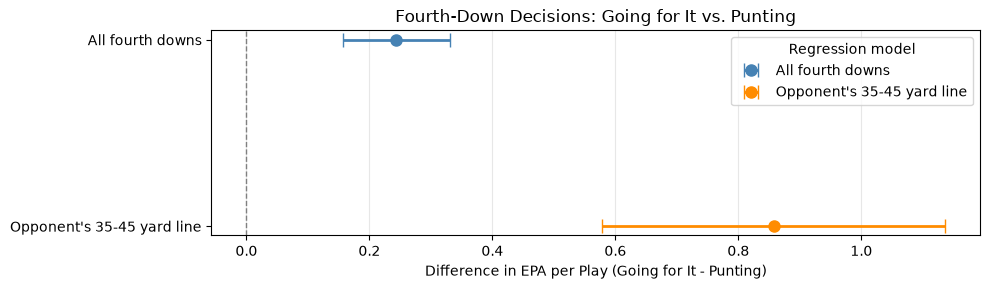

In [58]:
results = []

for model_name, fitted_model in [
    ("All fourth downs", fourthModel),
    ("Opponent's 35-45 yard line", fourthMidModel)
]:
    coefficients = fitted_model.params
    confidence_intervals = fitted_model.conf_int()

    results.append({"model": model_name,"estimate": coefficients[1],"lower": confidence_intervals[1][0],"upper": confidence_intervals[1][1]})

fig, ax = plt.subplots(figsize=(10, 3))

positions = [1, 0]
colors = ["steelblue", "darkorange"]

for i, result in enumerate(results):
    estimate = result["estimate"]

    lower_error = estimate - result["lower"]
    upper_error = result["upper"] - estimate

    ax.errorbar(
        estimate,
        positions[i],
        xerr=[[lower_error], [upper_error]],
        fmt="o",
        color=colors[i],
        capsize=5,
        markersize=8,
        linewidth=2,
        label=result["model"]
    )

ax.set_yticks(positions)
ax.set_yticklabels([r["model"] for r in results])

ax.axvline(0, color="gray", linestyle="--", linewidth=1)

ax.set_xlabel("Difference in EPA per Play (Going for It - Punting)")

ax.set_title("Fourth-Down Decisions: Going for It vs. Punting")

ax.legend(title="Regression model")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/finding-two.png", dpi=300, bbox_inches="tight")
plt.show()


The figure shows that going for it on fourth down has a positive and statistically significant association with EPA compared to punting. Across all fourth-down plays, going for it is associated with approximately 0.244 more EPA per play after controlling for yards to go and field position. When focusing on the opponent's 35–45 yard line, this difference increases to approximately 0.858 EPA per play. Both confidence intervals are above zero, suggesting that going for it is associated with higher EPA in both situations. Overall, these results suggest that going for it on fourth down may be more beneficial than punting, especially around the opponent's 40-yard line. However, these findings show an association rather than proving that going for it causes better outcomes.